# Módulo 03 

Notebook 2: Análisis exploratorio de datos (EDA)

> El EDA no es "hacer muchas gráficas": es **hacerle preguntas a los datos** y dejar que las respuestas guíen el modelado.

**Objetivos**
1. Entender la variable objetivo (`SalePrice`).
2. Explorar variables numéricas y categóricas, solas (**univariado**) y frente al target (**bivariado**).
3. Detectar *outliers* y decidir qué hacer con ellos.
4. **Validar las hipótesis** que planteamos en el módulo 02.
5. Salir con una lista de **variables candidatas** para el modelo.


In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from intro_analitica.datos import cargar_house_prices_limpio
from intro_analitica.eda import correlaciones_con_target, resumen_outliers

sns.set_theme(style="whitegrid")
df = cargar_house_prices_limpio()  # salida del notebook 1 (si no existe, se genera)
print(df.shape)

(1452, 86)


Trabajaremos con un subconjunto de variables:

| Variable | Tipo | Qué es | Unidad o valores |
|---|---|---|---|
| `LotArea` | Numérica | Área del terreno (lote) | Pies² |
| `OverallQual` | Numérica | Calidad general de materiales y acabados | De 1 (muy mala) a 10 (excelente) |
| `OverallCond` | Numérica | Estado general: qué tan bien se ha mantenido la casa | De 1 a 10 |
| `YearBuilt` | Numérica | Año de construcción | Año |
| `YearRemodAdd` | Numérica | Año de la última remodelación (igual a `YearBuilt` si nunca se remodeló) | Año |
| `GrLivArea` | Numérica | Área habitable sobre el nivel del suelo, sin el sótano | Pies² |
| `TotalBsmtSF` | Numérica | Área del sótano | Pies² |
| `FullBath` | Numérica | Baños completos sobre el nivel del suelo | Cantidad |
| `BedroomAbvGr` | Numérica | Habitaciones sobre el nivel del suelo | Cantidad |
| `GarageCars` | Numérica | Cupos de carro en el garaje | Cantidad |
| `HouseAge` | Numérica (nueva) | Edad de la casa al venderse: `YrSold − YearBuilt` | Años |
| `TotalSF` | Numérica (nueva) | Área total: sótano + primer piso + segundo piso | Pies² |
| `TotalBath` | Numérica (nueva) | Total de baños; los medios baños cuentan como 0,5 | Cantidad |
| `Neighborhood` | Categórica | Barrio de Ames donde está la casa | 25 barrios (NoRidge, CollgCr, Edwards…) |
| `BldgType` | Categórica | Tipo de edificación | `1Fam` (unifamiliar) · `2FmCon` (convertida para dos familias) · `Duplx` (dúplex) · `TwnhsE` (adosada de esquina) · `TwnhsI` (adosada del medio) |
| `HouseStyle` | Categórica | Estilo: cuántos pisos tiene | `1Story` (un piso) · `1.5Fin` (piso y medio) · `2Story` (dos pisos) · `SLvl` (multinivel) · `SFoyer` (entrada en desnivel) |
| `KitchenQual` | Categórica | Calidad de la cocina | `Ex` (excelente) · `Gd` (buena) · `TA` (típica) · `Fa` (regular) |
| `SaleCondition` | Categórica | Cómo se hizo la venta | `Normal` · `Abnorml` (remate o venta forzada) · `Partial` (casa nueva sin terminar) · `Family` (entre familiares) · `AdjLand` (terreno vecino) · `Alloca` (propiedades vinculadas) |
| `SalePrice` | Objetivo | Precio de venta | USD |

In [9]:
numericas = ["LotArea", "OverallQual", "OverallCond", "YearBuilt", "YearRemodAdd", "GrLivArea",
             "TotalBsmtSF", "FullBath", "BedroomAbvGr", "GarageCars", "HouseAge", "TotalSF", "TotalBath"]
categoricas = ["Neighborhood", "BldgType", "HouseStyle", "KitchenQual", "SaleCondition"]
target = "SalePrice"

house = df[numericas + categoricas + [target]]
house.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
LotArea,1452.0,10514.9,10003.6,1300.0,7538.8,9458.5,11601.5,215245.0
OverallQual,1452.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0
OverallCond,1452.0,5.6,1.1,1.0,5.0,5.0,6.0,9.0
YearBuilt,1452.0,1971.2,30.2,1872.0,1954.0,1972.5,2000.0,2010.0
YearRemodAdd,1452.0,1984.9,20.7,1950.0,1966.8,1994.0,2004.0,2010.0
GrLivArea,1452.0,1514.5,525.6,334.0,1128.0,1461.5,1776.0,5642.0
TotalBsmtSF,1452.0,1056.9,435.7,0.0,796.0,992.0,1298.2,6110.0
FullBath,1452.0,1.6,0.6,0.0,1.0,2.0,2.0,3.0
BedroomAbvGr,1452.0,2.9,0.8,0.0,2.0,3.0,3.0,8.0
GarageCars,1452.0,1.8,0.7,0.0,1.0,2.0,2.0,4.0


In [10]:
df["precio_m2"] = df["SalePrice"] / (df["GrLivArea"] * 0.0929)

kpis = {
    "Casas vendidas": len(df),
    "Ingreso total (USD M)": df["SalePrice"].sum() / 1e6,
    "Precio mediano (USD)": df["SalePrice"].median(),
    "Precio promedio (USD)": df["SalePrice"].mean(),
    "Precio mediano por m² (USD)": df["precio_m2"].median(),
}
for nombre, valor in kpis.items():
    print(f"{nombre:<30} {valor:>12,.0f}")

Casas vendidas                        1,452
Ingreso total (USD M)                   263
Precio mediano (USD)                162,950
Precio promedio (USD)               180,910
Precio mediano por m² (USD)           1,293


---
## 1. La variable objetivo

Siempre se empieza por aquí: **¿qué estamos prediciendo y cómo se distribuye?**

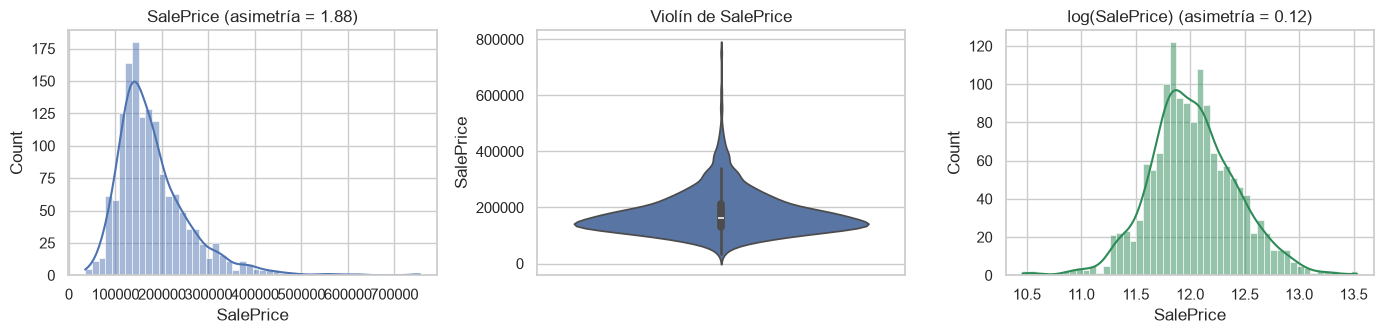

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
sns.histplot(house[target], bins=50, kde=True, ax=axes[0])
axes[0].set(title=f"SalePrice (asimetría = {house[target].skew():.2f})")
sns.violinplot(y=house[target], ax=axes[1])
axes[1].set(title="Violín de SalePrice")
sns.histplot(np.log1p(house[target]), bins=50, kde=True, ax=axes[2], color="seagreen")
axes[2].set(title=f"log(SalePrice) (asimetría = {np.log1p(house[target]).skew():.2f})")
plt.tight_layout()
plt.show()

**Lectura:**
### ¿Por qué usar el logaritmo del precio?

La idea es **cambiar la forma de medir las diferencias: de dólares a porcentajes**.

**1. Para el negocio, un error no pesa igual en todas las casas.**

| Casa | Precio real | Predicción | Error en USD | Error en % |
|---|---|---|---|---|
| Barata | 100.000 | 120.000 | 20.000 | **20 %** (grave) |
| Cara | 700.000 | 720.000 | 20.000 | **3 %** (pequeño) |

En dólares, los dos errores son iguales; en porcentaje, no. Con el logaritmo, el modelo **piensa en porcentajes**: subir de USD 100.000 a 120.000 y subir de USD 500.000 a 600.000 es el mismo salto, porque los dos son un 20 % más. El logaritmo no elimina los errores: los reparte de forma más justa. Sin logaritmo, el modelo tiende a ajustarse a las pocas casas caras y comete errores porcentuales grandes en las baratas. Con logaritmo, los errores quedan más parejos en porcentaje entre casas baratas y cara

**2. Corrige la cola larga.** El logaritmo comprime los valores grandes más que los pequeños: las pocas casas muy caras se acercan al resto y la asimetría baja de **1,88** a **0,12**, casi simétrica.

**Lo que NO hace:** no cambia el orden de las casas ni elimina los valores extremos. Ayuda sobre todo a la **regresión lineal**; los modelos de árboles casi no lo necesitan.

**Cómo se usa:** se entrena el modelo con `log(SalePrice)` y la predicción se devuelve a dólares con `np.exp()`. Por ejemplo, `np.exp(12.0)` ≈ USD 162.755.

---
## 2. Análisis univariado

### 2.1 Numéricas

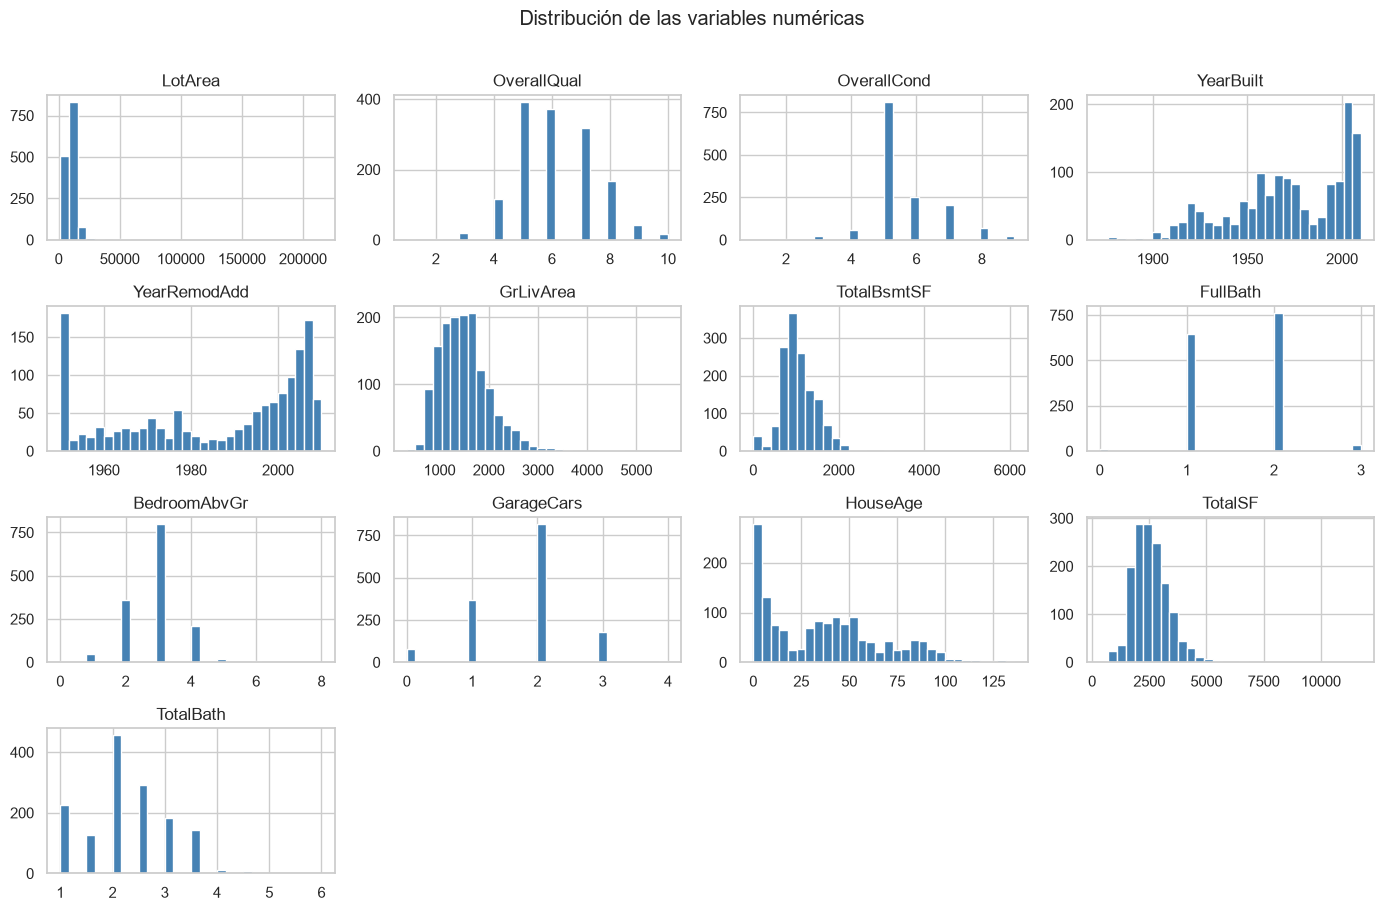

In [12]:
house[numericas].hist(bins=30, figsize=(14, 9), layout=(4, 4), color="steelblue")
plt.suptitle("Distribución de las variables numéricas", y=1.01)
plt.tight_layout()
plt.show()

**Qué buscar en estos histogramas:**

| Patrón | Ejemplo | Implicación |
|---|---|---|
| Cola larga | `LotArea`, `GrLivArea` | Posibles *outliers*; considerar logaritmo |
| Discreta / pocos valores | `OverallQual`, `FullBath`, `GarageCars` | Es ordinal o un conteo |
| Pico en 0 | `TotalBsmtSF` | Casas **sin** sótano (lo vimos en el notebook de preparación) |
| Bimodal | `YearBuilt` | Dos "olas" de construcción |

### 2.2 Categóricas

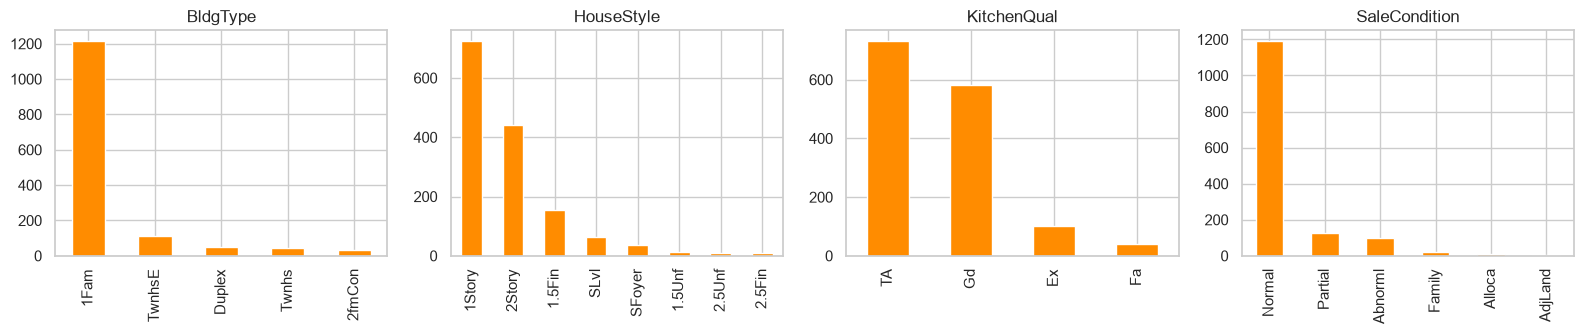

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["BldgType", "HouseStyle", "KitchenQual", "SaleCondition"]):
    house[col].value_counts().plot(kind="bar", ax=ax, color="darkorange")
    ax.set(title=col, xlabel="")
plt.tight_layout()
plt.show()

Hay categorías **dominantes** (`BldgType = 1Fam`, `SaleCondition = Normal`) y otras **raras** (pocas casas).
Las categorías raras son un riesgo: el modelo aprende poco de ellas, y en el one-hot generan columnas casi vacías.

---
## 3. Análisis bivariado: cada variable frente al precio

### 3.1 Correlaciones

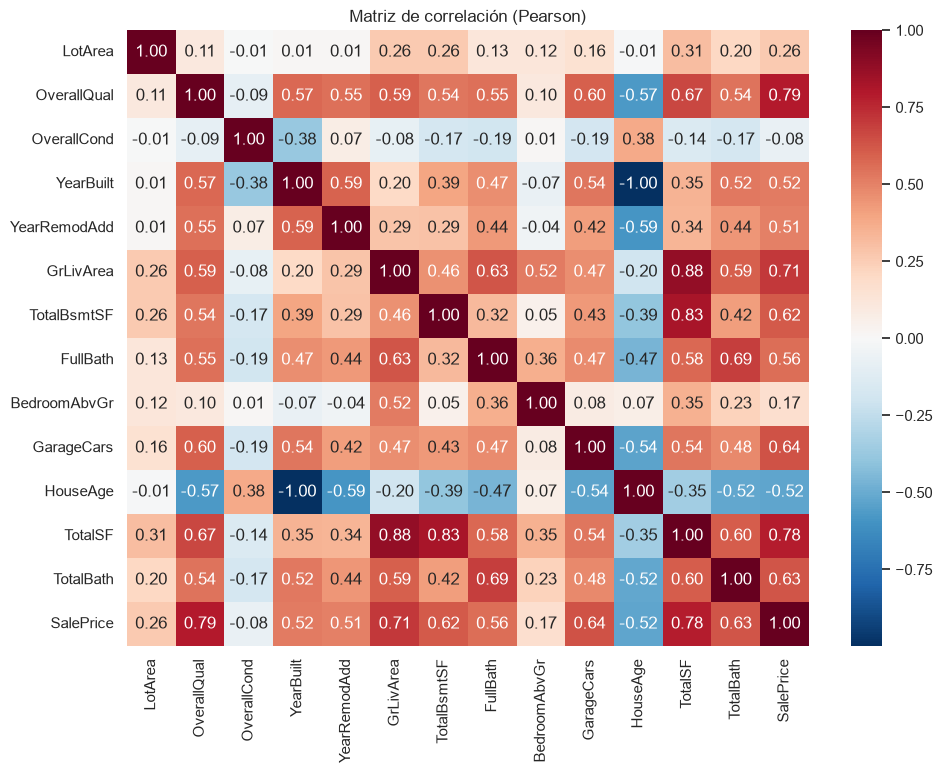

In [14]:
plt.figure(figsize=(11, 8))
sns.heatmap(house[numericas + [target]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Matriz de correlación (Pearson)")
plt.show()

In [15]:
correlaciones_con_target(house, target).to_frame("r_con_SalePrice")

,r_con_SalePrice
OverallQual,0.790888
TotalSF,0.782917
GrLivArea,0.709687
GarageCars,0.640087
TotalBath,0.631589
TotalBsmtSF,0.615103
FullBath,0.560226
YearBuilt,0.522765
YearRemodAdd,0.506507
LotArea,0.263728


**Dos lecturas de la matriz:**
1. **Frente al target:** `OverallQual` (0.79), `TotalSF` (0.78) y `GrLivArea` (0.71) son las variables más relacionadas con el precio.
2. **Entre variables (multicolinealidad):** `TotalSF` contiene a `TotalBsmtSF`; `HouseAge` y `YearBuilt` son casi la misma información (r ≈ -1). Usar ambas en una regresión lineal **no agrega información** y vuelve inestables los coeficientes.

> Pearson solo mide relaciones **lineales**. Una r baja no significa "no hay relación".

### 3.2 Numéricas vs. precio

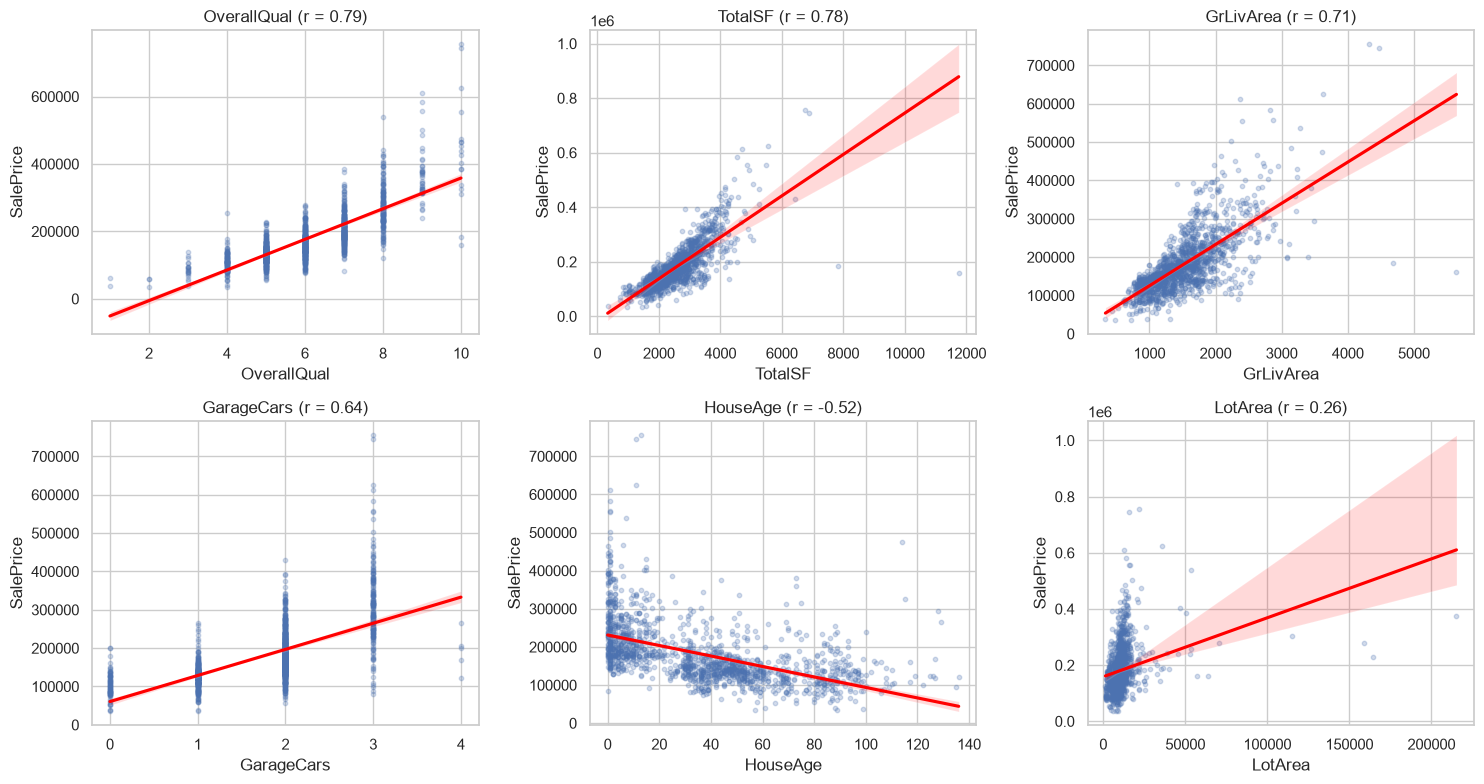

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["OverallQual", "TotalSF", "GrLivArea", "GarageCars", "HouseAge", "LotArea"]):
    sns.regplot(data=house, x=col, y=target, ax=ax, scatter_kws={"alpha": 0.25, "s": 10}, line_kws={"color": "red"})
    ax.set(title=f"{col} (r = {house[col].corr(house[target]):.2f})")
plt.tight_layout()
plt.show()

### 3.3 Categóricas vs. precio

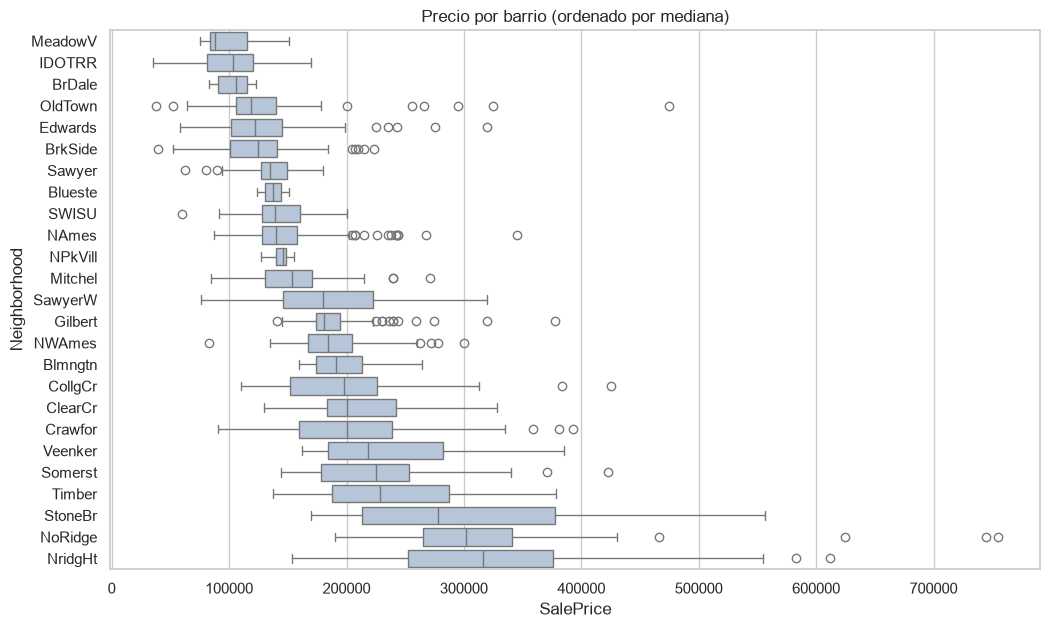

In [17]:
orden = house.groupby("Neighborhood")[target].median().sort_values().index
plt.figure(figsize=(12, 7))
sns.boxplot(data=house, y="Neighborhood", x=target, order=orden, color="lightsteelblue")
plt.title("Precio por barrio (ordenado por mediana)")
plt.show()

Entonces surge la pregunta: ¿el barrio vale por sí mismo, o solo porque tiene casas mejores? Para responderla hay que comparar casas de la misma calidad en distintos barrios.

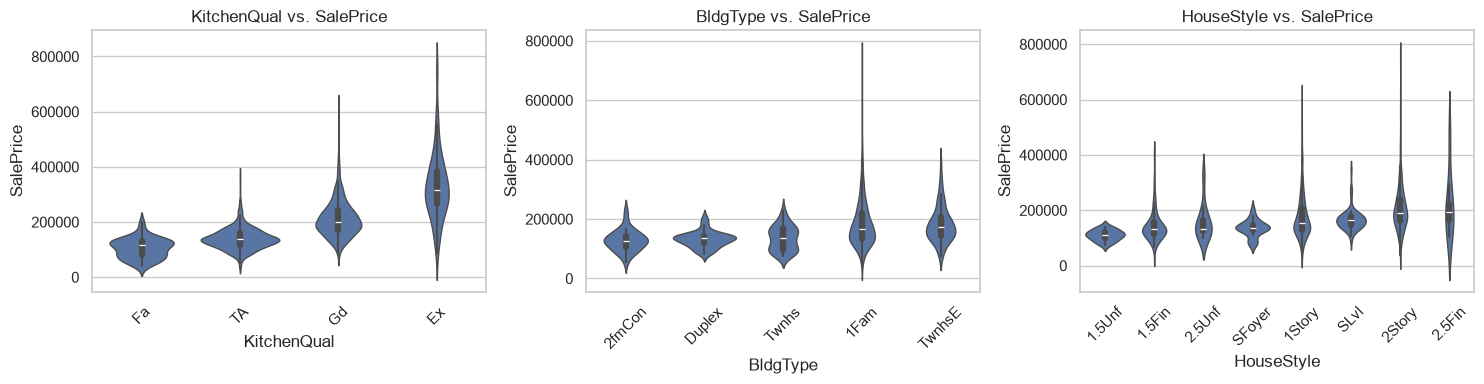

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["KitchenQual", "BldgType", "HouseStyle"]):
    orden_col = house.groupby(col)[target].median().sort_values().index
    sns.violinplot(data=house, x=col, y=target, order=orden_col, ax=ax, linewidth=1)
    ax.set(title=f"{col} vs. SalePrice")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

`KitchenQual` muestra una escalera muy clara: `Fa < TA < Gd < Ex`. Es **ordinal**, y el orden se refleja en el precio.

---
## 4. *Outliers*: detectar ≠ eliminar

### 4.1 Regla del IQR

In [19]:
resumen_outliers(house).head(8)
# La regla IQR marca como atípico lo que queda lejos de la mitad central de los datos.

,outliers,pct
TotalBath,393,27.1
OverallCond,125,8.6
LotArea,67,4.6
SalePrice,61,4.2
TotalBsmtSF,60,4.1
BedroomAbvGr,35,2.4
GrLivArea,31,2.1
TotalSF,24,1.7


¿`TotalBath` tiene un 27 % de *outliers*? No: es una variable **discreta** (1, 1.5, 2, 2.5…) con el IQR muy estrecho.
**La regla del IQR es una alerta, no una sentencia.** Siempre hay que mirar el gráfico y el contexto.

### 4.2 Los *outliers* famosos de House Prices

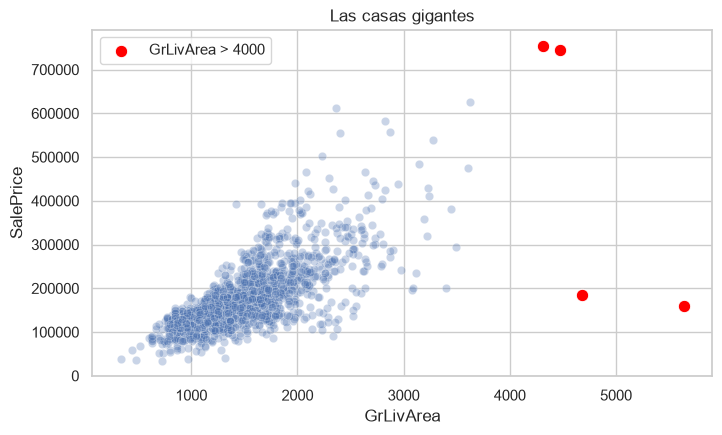

,GrLivArea,SalePrice,Neighborhood,SaleCondition,OverallQual
522,4676,184750,Edwards,Partial,10
689,4316,755000,NoRidge,Normal,10
1178,4476,745000,NoRidge,Abnorml,10
1293,5642,160000,Edwards,Partial,10


In [20]:
grandes = house[house["GrLivArea"] > 4000]
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=house, x="GrLivArea", y=target, alpha=0.3, ax=ax)
sns.scatterplot(data=grandes, x="GrLivArea", y=target, color="red", s=80, ax=ax, label="GrLivArea > 4000")
ax.set(title="Las casas gigantes")
plt.show()

df.loc[grandes.index, ["GrLivArea", "SalePrice", "Neighborhood", "SaleCondition", "OverallQual"]]

Dos casas **enormes** (>4.500 pies²) y de calidad 10 se vendieron **baratas** (~USD 170.000), las dos en `Edwards` y con `SaleCondition = Partial` (casas nuevas, vendidas antes de terminarse).

| Opción | Pros | Contras |
|---|---|---|
| Eliminarlas | Una regresión lineal no se "tuerce" por 2 puntos | Si llega una casa así, el modelo no la habrá visto |
| Dejarlas | Representan la realidad | Pueden dominar el error (RMSE) |
| Usar un modelo robusto | Los árboles son menos sensibles | — |

**Decisión para el curso:** las **dejamos en el dataset** y lo anotamos como riesgo. En el módulo 04 compararemos modelos con y sin ellas.
El propio autor del dataset (De Cock, 2011) recomienda quitar las casas de más de 4.000 pies² en ejercicios de clase.

---
## 5. Validación de hipótesis (del módulo 02)

### H1: la calidad general es el factor que más explica el precio

In [21]:
house.groupby("OverallQual")[target].agg(["size", "median"]).astype(int)

,size,median
OverallQual,,
1,2,50150
2,3,60000
3,20,86250
4,116,108000
5,393,133000
6,373,160000
7,317,200141
8,167,269500
9,43,345000


**Confirmada.** Tiene la mayor correlación (0.79) y una relación creciente y casi exponencial: cada punto de calidad sube el precio mediano entre un 20 % y un 45 %.

### H2: a mayor área, mayor precio (con *outliers*)
**Confirmada** (r = 0.71 para `GrLivArea`, 0.78 para `TotalSF`), con las 2 excepciones de `Edwards` vistas arriba.

### H3: el barrio influye aun comparando casas de la misma calidad

In [22]:
calidad_7 = house[house["OverallQual"] == 7]
por_barrio = calidad_7.groupby("Neighborhood")[target].agg(["size", "median"])
por_barrio[por_barrio["size"] >= 15].sort_values("median").astype(int)

,size,median
Neighborhood,,
OldTown,16,156000
Gilbert,35,185000
NWAmes,26,196750
Somerst,41,199900
CollgCr,70,204950
NridgHt,16,207250
SawyerW,21,228000


**Confirmada.** Entre casas de calidad 7 (y con al menos 15 ventas por barrio), el precio mediano va de ~USD 156.000 (`OldTown`) a ~USD 228.000 (`SawyerW`): un **46 % más** solo por la ubicación.

### H4: las casas remodeladas valen más que otras de la misma edad

In [23]:
house_h4 = house.assign(
    rango_edad=pd.cut(house["HouseAge"], bins=[-1, 10, 30, 50, 80], labels=["0-10", "11-30", "31-50", "51-80"]),
    remodelada=df["Remodeled"].map({0: "No", 1: "Sí"}),
)
tabla_h4 = house_h4.groupby(["rango_edad", "remodelada"], observed=True)[target].median().unstack()
tabla_h4["diferencia_%"] = ((tabla_h4["Sí"] / tabla_h4["No"] - 1) * 100).round(1)
tabla_h4

remodelada,No,Sí,diferencia_%
rango_edad,,,
0-10,213500.0,239000.0,11.9
11-30,185000.0,203250.0,9.9
31-50,140000.0,157000.0,12.1
51-80,125000.0,131000.0,4.8


**Confirmada (con matices).** En todos los rangos de edad, las remodeladas tienen una mediana mayor (entre un 5 % y un 12 %).

Si comparamos todas las remodeladas contra todas las no remodeladas, parece que remodelar baja el precio. Pero las remodeladas son mucho más viejas. Cuando comparamos casas de la misma edad, las remodeladas valen entre un 5 % y un 12 % más. La edad estaba escondiendo el efecto: eso es una variable de confusión. Antes de concluir, pregúntense siempre si están comparando grupos comparables.

---
## 6. Conclusiones del EDA (el entregable)

| # | Hallazgo | Implicación para el modelo |
|---|---|---|
| 1 | `SalePrice` es asimétrico; con log queda simétrico | Probar el target en escala log |
| 2 | `OverallQual`, `TotalSF`, `GrLivArea` y `GarageCars` son las variables más fuertes | Variables imprescindibles |
| 3 | El barrio importa aun controlando la calidad | Incluir `Neighborhood` (one-hot) |
| 4 | `KitchenQual` es ordinal y escalonada | Ordinal encoding u one-hot |
| 5 | `HouseAge` ≈ `YearBuilt` (r ≈ -1) | Usar solo una en los modelos lineales |
| 6 | 2 casas gigantes y baratas (`Partial`, `Edwards`) | Riesgo: evaluar con y sin ellas |
| 7 | El efecto de remodelar aparece solo comparando por edad | Los modelos multivariados lo captan; ojo con conclusiones univariadas |

En el **módulo 04** usaremos estos hallazgos para construir el *baseline* y los primeros modelos.

---
## Ejercicios guiados (20 min)

1. **Precio por m²:** crea `precio_m2 = SalePrice / (GrLivArea × 0.0929)`. ¿Cuál es el barrio más caro por m²? ¿Es el mismo que el más caro en precio total?
2. **Estacionalidad del precio:** el volumen de ventas sube en verano (módulo 02). ¿Y el **precio mediano**? Grafica la mediana de `SalePrice` por `MoSold`.
3. **Outliers con k = 3:** usa `outliers_iqr(serie, k=3)` sobre `LotArea`. ¿Cuántos quedan? Muéstralos en un scatter frente al precio.
4. **Una hipótesis nueva:** plantea y valida una (p.ej. "las casas con chimenea valen más", usando `Fireplaces`).

Soluciones en `ejercicios/soluciones/solucion_02_eda.py`.